In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA

In [2]:
# Load the Breast Cancer Wisconsin dataset
df = pd.read_csv("wdbc.data", header=None)

# Display the first five records
print(df.head())

# Display the dataset dimensions
print("Dataset shape:", df.shape)

         0  1      2      3       4       5        6        7       8   \
0    842302  M  17.99  10.38  122.80  1001.0  0.11840  0.27760  0.3001   
1    842517  M  20.57  17.77  132.90  1326.0  0.08474  0.07864  0.0869   
2  84300903  M  19.69  21.25  130.00  1203.0  0.10960  0.15990  0.1974   
3  84348301  M  11.42  20.38   77.58   386.1  0.14250  0.28390  0.2414   
4  84358402  M  20.29  14.34  135.10  1297.0  0.10030  0.13280  0.1980   

        9   ...     22     23      24      25      26      27      28      29  \
0  0.14710  ...  25.38  17.33  184.60  2019.0  0.1622  0.6656  0.7119  0.2654   
1  0.07017  ...  24.99  23.41  158.80  1956.0  0.1238  0.1866  0.2416  0.1860   
2  0.12790  ...  23.57  25.53  152.50  1709.0  0.1444  0.4245  0.4504  0.2430   
3  0.10520  ...  14.91  26.50   98.87   567.7  0.2098  0.8663  0.6869  0.2575   
4  0.10430  ...  22.54  16.67  152.20  1575.0  0.1374  0.2050  0.4000  0.1625   

       30       31  
0  0.4601  0.11890  
1  0.2750  0.08902  
2  0.

In [3]:
# Separate input features and target labels
X = df.iloc[:, 2:]
y = df.iloc[:, 1]

# Display the features and target labels
print("Features:")
print(X.head())

print("\nDiagnosis labels:")
print(y.head())

print("\nNumber of features:", X.shape[1])

Features:
      2      3       4       5        6        7       8        9       10  \
0  17.99  10.38  122.80  1001.0  0.11840  0.27760  0.3001  0.14710  0.2419   
1  20.57  17.77  132.90  1326.0  0.08474  0.07864  0.0869  0.07017  0.1812   
2  19.69  21.25  130.00  1203.0  0.10960  0.15990  0.1974  0.12790  0.2069   
3  11.42  20.38   77.58   386.1  0.14250  0.28390  0.2414  0.10520  0.2597   
4  20.29  14.34  135.10  1297.0  0.10030  0.13280  0.1980  0.10430  0.1809   

        11  ...     22     23      24      25      26      27      28      29  \
0  0.07871  ...  25.38  17.33  184.60  2019.0  0.1622  0.6656  0.7119  0.2654   
1  0.05667  ...  24.99  23.41  158.80  1956.0  0.1238  0.1866  0.2416  0.1860   
2  0.05999  ...  23.57  25.53  152.50  1709.0  0.1444  0.4245  0.4504  0.2430   
3  0.09744  ...  14.91  26.50   98.87   567.7  0.2098  0.8663  0.6869  0.2575   
4  0.05883  ...  22.54  16.67  152.20  1575.0  0.1374  0.2050  0.4000  0.1625   

       30       31  
0  0.4601  0.

In [5]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [6]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data standardized:", X_train_scaled.shape)
print("Testing data standardized:", X_test_scaled.shape)

Training data standardized: (455, 30)
Testing data standardized: (114, 30)


In [7]:
# Create SVM models using different kernels
svm_linear = SVC(kernel="linear")
svm_poly = SVC(kernel="poly")
svm_rbf = SVC(kernel="rbf")

# Train each model using the standardized training data
svm_linear.fit(X_train_scaled, y_train)
svm_poly.fit(X_train_scaled, y_train)
svm_rbf.fit(X_train_scaled, y_train)

print("SVM models with Linear, Polynomial, and RBF kernels trained successfully.")

SVM models with Linear, Polynomial, and RBF kernels trained successfully.


In [8]:
# Predict the diagnosis using each SVM model
y_pred_linear = svm_linear.predict(X_test_scaled)
y_pred_poly = svm_poly.predict(X_test_scaled)
y_pred_rbf = svm_rbf.predict(X_test_scaled)

# Calculate and display the accuracy of each model
print("Linear Kernel Accuracy:", accuracy_score(y_test, y_pred_linear))
print("Polynomial Kernel Accuracy:", accuracy_score(y_test, y_pred_poly))
print("RBF Kernel Accuracy:", accuracy_score(y_test, y_pred_rbf))

Linear Kernel Accuracy: 0.9649122807017544
Polynomial Kernel Accuracy: 0.8859649122807017
RBF Kernel Accuracy: 0.9736842105263158


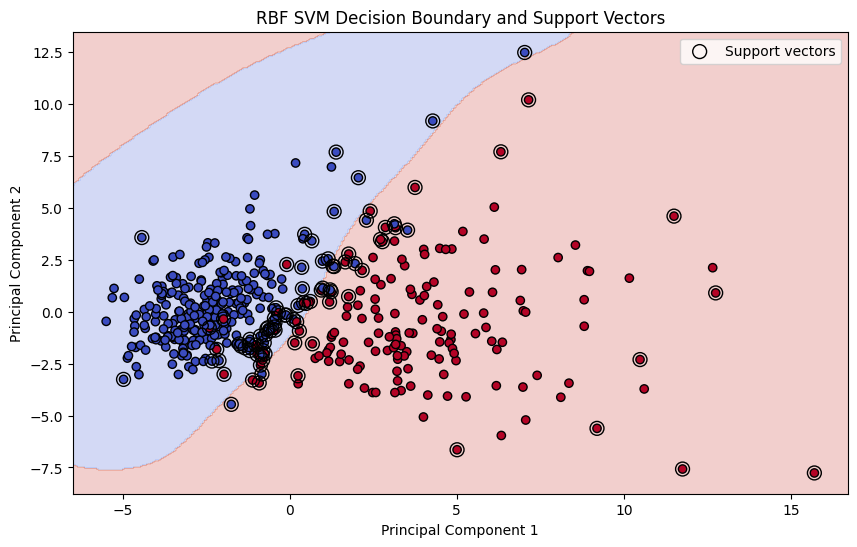

In [10]:
# Predict classes for each point in the grid
Z = svm_visual.predict(np.c_[xx.ravel(), yy.ravel()])

# Convert string labels into numeric values
Z = (Z == "M").astype(int).reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

# Plot the training samples
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=(y_train == "M").astype(int),
    cmap="coolwarm",
    edgecolors="k"
)

# Highlight the support vectors
plt.scatter(
    svm_visual.support_vectors_[:, 0],
    svm_visual.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    label="Support vectors"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("RBF SVM Decision Boundary and Support Vectors")
plt.legend()
plt.show()

In [11]:
# Define the values of C and gamma to test
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

# Create GridSearchCV for the RBF kernel
grid_search = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Train and tune the model
grid_search.fit(X_train_scaled, y_train)

# Display the best parameters and cross-validation accuracy
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 0.01}
Best Cross-Validation Accuracy: 0.9758241758241759


In [12]:
# Get the best RBF SVM model from GridSearchCV
best_rbf = grid_search.best_estimator_

# Predict the diagnosis using the tuned model
y_pred_best = best_rbf.predict(X_test_scaled)

# Calculate the accuracy of the tuned model
tuned_accuracy = accuracy_score(y_test, y_pred_best)

# Compare the original and tuned RBF models
original_accuracy = accuracy_score(y_test, y_pred_rbf)

print("Original RBF SVM Accuracy:", original_accuracy)
print("Tuned RBF SVM Accuracy:", tuned_accuracy)
print("Best Parameters:", grid_search.best_params_)

Original RBF SVM Accuracy: 0.9736842105263158
Tuned RBF SVM Accuracy: 0.9824561403508771
Best Parameters: {'C': 10, 'gamma': 0.01}


In [13]:
# Display the confusion matrix for the tuned RBF model
cm = confusion_matrix(y_test, y_pred_best, labels=["B", "M"])

print("Confusion Matrix:")
print(cm)

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, labels=["B", "M"]))

Confusion Matrix:
[[72  0]
 [ 2 40]]

Classification Report:
              precision    recall  f1-score   support

           B       0.97      1.00      0.99        72
           M       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

